# Aula 21 — Árvores Binárias na Fábrica de Paçoca: BDT do Forno de Torra e AVL do Historiador SCADA

**Disciplina:** ECAA08 — Automática (2026.2) — UNIFEI  
**Projeto:** SCADA-Core Automática / Linha de Produção de Paçoca  
**Equipe:** Grupo 7  

Este notebook valida duas aplicações de árvores binárias no **Setor 200 (Torra e Despeliculagem, CLP 02)**:

1. **Árvore Binária de Decisão (BDT)** para o intertravamento (SIS) do Forno de Torra, com avaliação em tempo constante $O(1)$.
2. **Árvore AVL** (busca auto-balanceada) como índice de *timestamps* do Historiador SCADA, para consultas $O(\log N)$ usadas em análise de causa-raiz (RCA) e rastreabilidade de lote (APPCC).

## Objetivos
1. Gerar telemetria sintética do forno com falhas injetadas.
2. Implementar a BDT e **provar, por enumeração exaustiva das 32 combinações de entrada**, que ela equivale à regra de trip da Etapa 01: $\text{Trip}_{\text{Forno}} \equiv \neg f_2 \lor t_2 \lor e_1$.
3. Implementar a AVL, verificar seus invariantes e comparar com busca linear e com uma BST sem balanceamento.
4. Visualizar o processo e as atuações do SIS.

In [1]:
import time
from dataclasses import dataclass
from itertools import product
from typing import Any, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

---
## 1. Telemetria Sintética do Forno de Torra

Catálogo ISA-5.1 do Setor 200 (Etapa 01), discretizado a partir de sinais analógicos:

| Tag | Variável | Proposição | Regra de discretização |
| :--- | :--- | :---: | :--- |
| `TT-201` | Temperatura do forno | $t_2$ | $t_2 = 1$ se $T > 160^\circ\text{C}$ |
| `TS-201` | Chama do queimador | $c_1$ | $c_1 = 1$ se chama detectada |
| `FS-201` | Fluxo de exaustão | $f_2$ | $f_2 = 1$ se fluxo $\ge 50\%$ do nominal |
| `M-201` | Esteira do forno | $m_2$ | $m_2 = 1$ se ligada |
| `ESD-100` | Parada de emergência | $e_1$ | $e_1 = 1$ se acionada |

Atuadores: `XV-201` (válvula de corte de gás), `M-201` (esteira) e `ALM-201` (alarme).

> A amostragem é de 100 ms (10 Hz) e as falhas são **injetadas** em janelas conhecidas, para podermos conferir se o SIS e o historiador as encontram.

In [2]:
T_INICIO_MS = 1_794_934_800_000          # 17/11/2026 17:00:00 UTC, em ms
PASSO_MS = 100

def gerar_telemetria(n: int = 2000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    ts = T_INICIO_MS + np.arange(n) * PASSO_MS

    # TT-201: nominal ~148 °C (abaixo do limite de 160 °C) + ondulação do PID + ruído
    temp = 148 + 5 * np.sin(np.linspace(0, 8 * np.pi, n)) + rng.normal(0, 1.2, n)
    temp[600:680] += np.linspace(0, 20, 80)      # rampa de sobretemperatura
    temp[680:730] += 20

    # FS-201: exaustão nominal ~85 % do fluxo, com queda por entupimento
    fluxo = 85 + rng.normal(0, 2.5, n)
    fluxo[1200:1260] -= np.linspace(0, 55, 60)
    fluxo[1260:1320] -= 55

    # TS-201: chama presente, com perda temporária
    chama = np.ones(n, dtype=int); chama[1500:1540] = 0

    # M-201: esteira ligada, com parada temporária
    esteira = np.ones(n, dtype=int); esteira[300:360] = 0

    # ESD-100: acionamento manual
    esd = np.zeros(n, dtype=int); esd[1850:1870] = 1

    # Rastreabilidade (APPCC): um lote a cada 500 amostras
    lote = [f"L-20261117-{i // 500 + 1:02d}" for i in range(n)]

    return pd.DataFrame({
        'timestamp_ms': ts, 'TT_201_degC': np.round(temp, 2), 'FS_201_pct': np.round(fluxo, 2),
        'TS_201_chama': chama, 'M_201_esteira': esteira, 'ESD_100': esd, 'lote': lote,
    })

df = gerar_telemetria()
df['t2'] = (df['TT_201_degC'] > 160).astype(int)
df['f2'] = (df['FS_201_pct'] >= 50).astype(int)
print(f"✅ {len(df)} amostras geradas ({len(df) * PASSO_MS / 1000:.0f} s de operação)")
df.head()

✅ 2000 amostras geradas (200 s de operação)


,timestamp_ms,TT_201_degC,FS_201_pct,TS_201_chama,M_201_esteira,ESD_100,lote,t2,f2
0,1794934800000,148.37,83.87,1,1,0,L-20261117-01,0,1
1,1794934800100,146.81,83.34,1,1,0,L-20261117-01,0,1
2,1794934800200,149.03,86.09,1,1,0,L-20261117-01,0,1
3,1794934800300,149.32,85.63,1,1,0,L-20261117-01,0,1
4,1794934800400,145.91,81.49,1,1,0,L-20261117-01,0,1


---
## 2. Árvore Binária de Decisão (BDT) — SIS do Forno

Os predicados são avaliados em **ordem decrescente de severidade**, com curto-circuito (a primeira condição verdadeira decide):

| Nível | Predicado | Estado | `XV-201` | `M-201` | `ALM-201` |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 0 | $e_1 = 1$ (`ESD-100`) | `TRIP_ESD` | 0 | 0 | 1 |
| 1 | $t_2 = 1$ (`TT-201`) | `TRIP_SOBRETEMPERATURA` | 0 | 1 | 1 |
| 2 | $f_2 = 0$ (`FS-201`) | `TRIP_FALHA_EXAUSTAO` | 0 | 1 | 1 |
| 3 | $c_1 = 0$ (`TS-201`) | `TRIP_PERDA_CHAMA` | 0 | 1 | 1 |
| 4 | $m_2 = 0$ (`M-201`) | `BLOQUEIO_ESTEIRA_PARADA` | 0 | 0 | 1 |
| 5 | (nenhum) | `OPERACAO_NORMAL` | 1 | 1 | 0 |

Nos trips térmicos e de exaustão a esteira **continua ligada** para descarregar o forno e evitar que a carga queime; no `ESD-100` tudo é desenergizado.

In [3]:
@dataclass(frozen=True)
class EstadoSIS:
    xv201: int      # válvula de corte de gás (1 = aberta)
    m201: int       # esteira do forno (1 = ligada)
    alm201: int     # alarme (1 = ativado)
    status: str

class BDT_SIS_Forno:
    # Árvore binária de decisão de profundidade fixa h = 5 para o forno de torra (Setor 200)

    @staticmethod
    def avaliar(e1: int, t2: int, f2: int, c1: int, m2: int) -> EstadoSIS:
        if e1 == 1:  return EstadoSIS(0, 0, 1, "TRIP_ESD")
        if t2 == 1:  return EstadoSIS(0, 1, 1, "TRIP_SOBRETEMPERATURA")
        if f2 == 0:  return EstadoSIS(0, 1, 1, "TRIP_FALHA_EXAUSTAO")
        if c1 == 0:  return EstadoSIS(0, 1, 1, "TRIP_PERDA_CHAMA")
        if m2 == 0:  return EstadoSIS(0, 0, 1, "BLOQUEIO_ESTEIRA_PARADA")
        return EstadoSIS(1, 1, 0, "OPERACAO_NORMAL")

# --- Prova por enumeração exaustiva: 2^5 = 32 combinações de entrada ---
violacoes = []
for e1, t2, f2, c1, m2 in product([0, 1], repeat=5):
    est = BDT_SIS_Forno.avaliar(e1, t2, f2, c1, m2)
    gas_aberto = bool(est.xv201)
    # (a) Regra da Etapa 01: Trip_Forno = ¬f2 ∨ t2 ∨ e1  =>  gás DEVE estar fechado
    if (not f2 or t2 or e1) and gas_aberto:
        violacoes.append(('Etapa01', e1, t2, f2, c1, m2))
    # (b) Gás só abre se TODAS as condições seguras valem
    seguro = (not e1) and (not t2) and f2 and c1 and m2
    if gas_aberto != bool(seguro):
        violacoes.append(('Equivalencia', e1, t2, f2, c1, m2))

print(f"Combinações testadas: 32 | Violações encontradas: {len(violacoes)}")
print("✅ BDT ≡ regra de trip da Etapa 01 e XV-201 só abre em condição 100% segura" if not violacoes else violacoes)

Combinações testadas: 32 | Violações encontradas: 0
✅ BDT ≡ regra de trip da Etapa 01 e XV-201 só abre em condição 100% segura


In [4]:
# Processa toda a telemetria pela BDT
t0 = time.perf_counter()
res = [BDT_SIS_Forno.avaliar(r.ESD_100, r.t2, r.f2, r.TS_201_chama, r.M_201_esteira) for r in df.itertuples()]
t1 = time.perf_counter()

df['XV_201'] = [r.xv201 for r in res]
df['M_201_cmd'] = [r.m201 for r in res]
df['ALM_201'] = [r.alm201 for r in res]
df['Status_SIS'] = [r.status for r in res]

print(f"⏱️ {len(df)} varreduras em {(t1 - t0) * 1000:.2f} ms  ->  {(t1 - t0) / len(df) * 1e6:.2f} µs por varredura (profundidade fixa, O(1))")
print("\n📊 Distribuição de estados do SIS:")
df['Status_SIS'].value_counts()

⏱️ 2000 varreduras em 5.26 ms  ->  2.63 µs por varredura (profundidade fixa, O(1))

📊 Distribuição de estados do SIS:


Status_SIS
OPERACAO_NORMAL            1700
TRIP_SOBRETEMPERATURA       100
TRIP_FALHA_EXAUSTAO          80
BLOQUEIO_ESTEIRA_PARADA      60
TRIP_PERDA_CHAMA             40
TRIP_ESD                     20
Name: count, dtype: int64

---
## 3. Árvore AVL — Índice Temporal do Historiador SCADA

Cada nó guarda o *timestamp* $\tau$ (ms) como chave e a telemetria como *payload*. Como as amostras chegam **em ordem crescente de $\tau$**, uma BST comum degeneraria em uma lista encadeada ($h = N$, busca $O(N)$). A AVL mantém $|BF(n)| \le 1$ por rotações, garantindo $h = O(\log N)$.

$$BF(n) = h(\text{direita}) - h(\text{esquerda}) \in \{-1, 0, +1\}$$

In [5]:
class NoAVL:
    __slots__ = ('timestamp', 'payload', 'altura', 'esquerda', 'direita')
    def __init__(self, timestamp: int, payload: Dict[str, Any]):
        self.timestamp, self.payload, self.altura = timestamp, payload, 1
        self.esquerda: Optional['NoAVL'] = None
        self.direita: Optional['NoAVL'] = None

class HistoriadorAVL:
    def __init__(self):
        self.raiz: Optional[NoAVL] = None
        self.tamanho = 0
        self.rotacoes = 0

    # --- utilitários de altura e balanceamento ---
    @staticmethod
    def altura(no): return no.altura if no else 0
    def bf(self, no): return self.altura(no.direita) - self.altura(no.esquerda) if no else 0
    def _atualiza(self, no): no.altura = 1 + max(self.altura(no.esquerda), self.altura(no.direita))

    # --- rotações simples ---
    def _rot_direita(self, y):
        x = y.esquerda; y.esquerda = x.direita; x.direita = y
        self._atualiza(y); self._atualiza(x); self.rotacoes += 1
        return x
    def _rot_esquerda(self, x):
        y = x.direita; x.direita = y.esquerda; y.esquerda = x
        self._atualiza(x); self._atualiza(y); self.rotacoes += 1
        return y

    def _rebalancear(self, no):
        self._atualiza(no)
        b = self.bf(no)
        if b < -1:                                   # pesada à esquerda
            if self.bf(no.esquerda) > 0:             # caso LR
                no.esquerda = self._rot_esquerda(no.esquerda)
            return self._rot_direita(no)             # caso LL
        if b > 1:                                    # pesada à direita
            if self.bf(no.direita) < 0:              # caso RL
                no.direita = self._rot_direita(no.direita)
            return self._rot_esquerda(no)            # caso RR
        return no

    # --- operações públicas ---
    def inserir(self, ts: int, payload: Dict[str, Any]):
        self.raiz = self._ins(self.raiz, ts, payload)

    def _ins(self, no, ts, payload):
        if no is None:
            self.tamanho += 1
            return NoAVL(ts, payload)
        if ts < no.timestamp:   no.esquerda = self._ins(no.esquerda, ts, payload)
        elif ts > no.timestamp: no.direita = self._ins(no.direita, ts, payload)
        else:
            no.payload = payload                     # mesma chave: atualiza registro
            return no
        return self._rebalancear(no)

    def buscar(self, ts: int) -> Optional[Dict[str, Any]]:
        no = self.raiz
        while no:
            if ts == no.timestamp: return no.payload
            no = no.esquerda if ts < no.timestamp else no.direita
        return None

    def intervalo(self, t_ini: int, t_fim: int) -> List[Tuple[int, Dict[str, Any]]]:
        out: List[Tuple[int, Dict[str, Any]]] = []
        def rec(no):
            if not no: return
            if no.timestamp > t_ini: rec(no.esquerda)          # poda à esquerda
            if t_ini <= no.timestamp <= t_fim: out.append((no.timestamp, no.payload))
            if no.timestamp < t_fim: rec(no.direita)           # poda à direita
        rec(self.raiz)
        return out

    def em_ordem(self):
        pilha, no = [], self.raiz
        while pilha or no:
            while no: pilha.append(no); no = no.esquerda
            no = pilha.pop(); yield no.timestamp
            no = no.direita

    def invariantes_ok(self) -> bool:
        # Confere |BF| <= 1, alturas corretas e ordenação estrita das chaves
        def rec(no):
            if not no: return 0, True
            he, ok_e = rec(no.esquerda); hd, ok_d = rec(no.direita)
            ok = ok_e and ok_d and abs(hd - he) <= 1 and no.altura == 1 + max(he, hd)
            return 1 + max(he, hd), ok
        chaves = list(self.em_ordem())
        return rec(self.raiz)[1] and chaves == sorted(set(chaves))

# Exemplo mínimo: 3 inserções crescentes disparam uma rotação RR
mini = HistoriadorAVL()
for k in (100, 200, 300): mini.inserir(k, {})
print(f"Raiz após inserir 100, 200, 300: {mini.raiz.timestamp} | rotações: {mini.rotacoes} | invariantes: {mini.invariantes_ok()}")

Raiz após inserir 100, 200, 300: 200 | rotações: 1 | invariantes: True


---
## 4. Povoamento, Invariantes e Benchmark

Povoamos a AVL com a telemetria do forno e comparamos com (a) busca linear e (b) uma BST **sem** balanceamento recebendo as mesmas chaves crescentes.

In [6]:
hist = HistoriadorAVL()
t0 = time.perf_counter()
for r in df.itertuples():
    hist.inserir(r.timestamp_ms, {'TT_201': r.TT_201_degC, 'FS_201': r.FS_201_pct, 'XV_201': r.XV_201,
                                  'Status_SIS': r.Status_SIS, 'lote': r.lote})
t_ins = (time.perf_counter() - t0) * 1000

N = len(df)
print(f"✅ {hist.tamanho} registros inseridos em {t_ins:.1f} ms | rotações executadas: {hist.rotacoes}")
print(f"🌲 Altura da AVL: {hist.altura(hist.raiz)} (limite teórico ≈ 1,44·log2(N) = {1.44 * np.log2(N):.1f}; mínimo possível = {int(np.ceil(np.log2(N + 1)))})")
print(f"🔒 Invariantes AVL (|BF| ≤ 1, alturas, ordenação): {'OK ✅' if hist.invariantes_ok() else 'FALHOU ❌'}")

# BST sem balanceamento (iterativa, para não estourar a recursão) com as mesmas chaves crescentes
def altura_bst_degenerada(chaves):
    esq, dir_, raiz, alt = {}, {}, None, 0
    for k in chaves:
        if raiz is None: raiz = k; alt = 1; continue
        atual, d = raiz, 1
        while True:
            d += 1
            lado = esq if k < atual else dir_
            if atual in lado and lado[atual] is not None: atual = lado[atual]
            else: lado[atual] = k; break
        alt = max(alt, d)
    return alt
print(f"⚠️ BST sem balanceamento com as mesmas chaves: altura = {altura_bst_degenerada(df['timestamp_ms'])} (vira uma lista)")

✅ 2000 registros inseridos em 21.0 ms | rotações executadas: 1989
🌲 Altura da AVL: 11 (limite teórico ≈ 1,44·log2(N) = 15.8; mínimo possível = 11)
🔒 Invariantes AVL (|BF| ≤ 1, alturas, ordenação): OK ✅


⚠️ BST sem balanceamento com as mesmas chaves: altura = 2000 (vira uma lista)


In [7]:
alvo = int(df.iloc[1250]['timestamp_ms'])
REP = 2000

t0 = time.perf_counter()
for _ in range(REP): r_avl = hist.buscar(alvo)
t_avl = (time.perf_counter() - t0) / REP * 1e6

lista = list(zip(df['timestamp_ms'], df['Status_SIS']))
def busca_linear(a):
    for ts, st in lista:
        if ts == a: return st
t0 = time.perf_counter()
for _ in range(REP): r_lin = busca_linear(alvo)
t_lin = (time.perf_counter() - t0) / REP * 1e6

assert r_avl['Status_SIS'] == r_lin
print(f"🎯 Busca pontual (amostra 1250): AVL {t_avl:.2f} µs | linear {t_lin:.2f} µs | AVL ≈ {t_lin / t_avl:.0f}x mais rápida")

# Consulta por intervalo, conferida contra filtro do pandas
t_ini, t_fim = int(df.iloc[500]['timestamp_ms']), int(df.iloc[700]['timestamp_ms'])
r_int = hist.intervalo(t_ini, t_fim)
esperado = df[(df.timestamp_ms >= t_ini) & (df.timestamp_ms <= t_fim)]
print(f"🔍 Intervalo [{t_ini}, {t_fim}]: AVL retornou {len(r_int)} nós | pandas {len(esperado)} | iguais e ordenados: "
      f"{[k for k, _ in r_int] == list(esperado.timestamp_ms)}")

🎯 Busca pontual (amostra 1250): AVL 0.68 µs | linear 30.35 µs | AVL ≈ 45x mais rápida
🔍 Intervalo [1794934850000, 1794934870000]: AVL retornou 201 nós | pandas 201 | iguais e ordenados: True


### 4.1 Aplicação: análise de causa-raiz (RCA) e rastreabilidade de lote

Dois usos reais do historiador: (1) recuperar a janela de ±2 s em torno do **primeiro trip por sobretemperatura**, e (2) listar quais lotes estavam no forno durante um evento (APPCC).

In [8]:
trip = df[df.Status_SIS == 'TRIP_SOBRETEMPERATURA'].iloc[0]
tau = int(trip.timestamp_ms)
janela = hist.intervalo(tau - 2000, tau + 2000)
print(f"Primeiro trip por sobretemperatura em τ = {tau} (T = {trip.TT_201_degC} °C, amostra {trip.name})")
print(f"Janela RCA ±2 s: {len(janela)} registros recuperados da AVL\n")

rca = pd.DataFrame([{'τ (ms)': ts, 'TT-201 (°C)': p['TT_201'], 'Status SIS': p['Status_SIS'], 'XV-201': p['XV_201']} for ts, p in janela])
display(rca.iloc[::5].reset_index(drop=True))

lotes_afetados = sorted({p['lote'] for _, p in hist.intervalo(int(df[df.Status_SIS == 'TRIP_SOBRETEMPERATURA'].timestamp_ms.min()),
                                                              int(df[df.Status_SIS == 'TRIP_SOBRETEMPERATURA'].timestamp_ms.max()))})
print("Lote(s) no forno durante a sobretemperatura (para segregação/análise):", lotes_afetados)

Primeiro trip por sobretemperatura em τ = 1794934862700 (T = 161.47 °C, amostra 627)
Janela RCA ±2 s: 41 registros recuperados da AVL



,τ (ms),TT-201 (°C),Status SIS,XV-201
0,1794934860700,155.19,OPERACAO_NORMAL,1
1,1794934861200,154.27,OPERACAO_NORMAL,1
2,1794934861700,157.57,OPERACAO_NORMAL,1
3,1794934862200,158.89,OPERACAO_NORMAL,1
4,1794934862700,161.47,TRIP_SOBRETEMPERATURA,0
5,1794934863200,160.59,TRIP_SOBRETEMPERATURA,0
6,1794934863700,160.97,TRIP_SOBRETEMPERATURA,0
7,1794934864200,165.98,TRIP_SOBRETEMPERATURA,0
8,1794934864700,162.63,TRIP_SOBRETEMPERATURA,0


Lote(s) no forno durante a sobretemperatura (para segregação/análise): ['L-20261117-02']


---
## 5. Visualização Integrada

Variáveis do forno com os limites do SIS, e o estado dos atuadores comandados pela BDT.

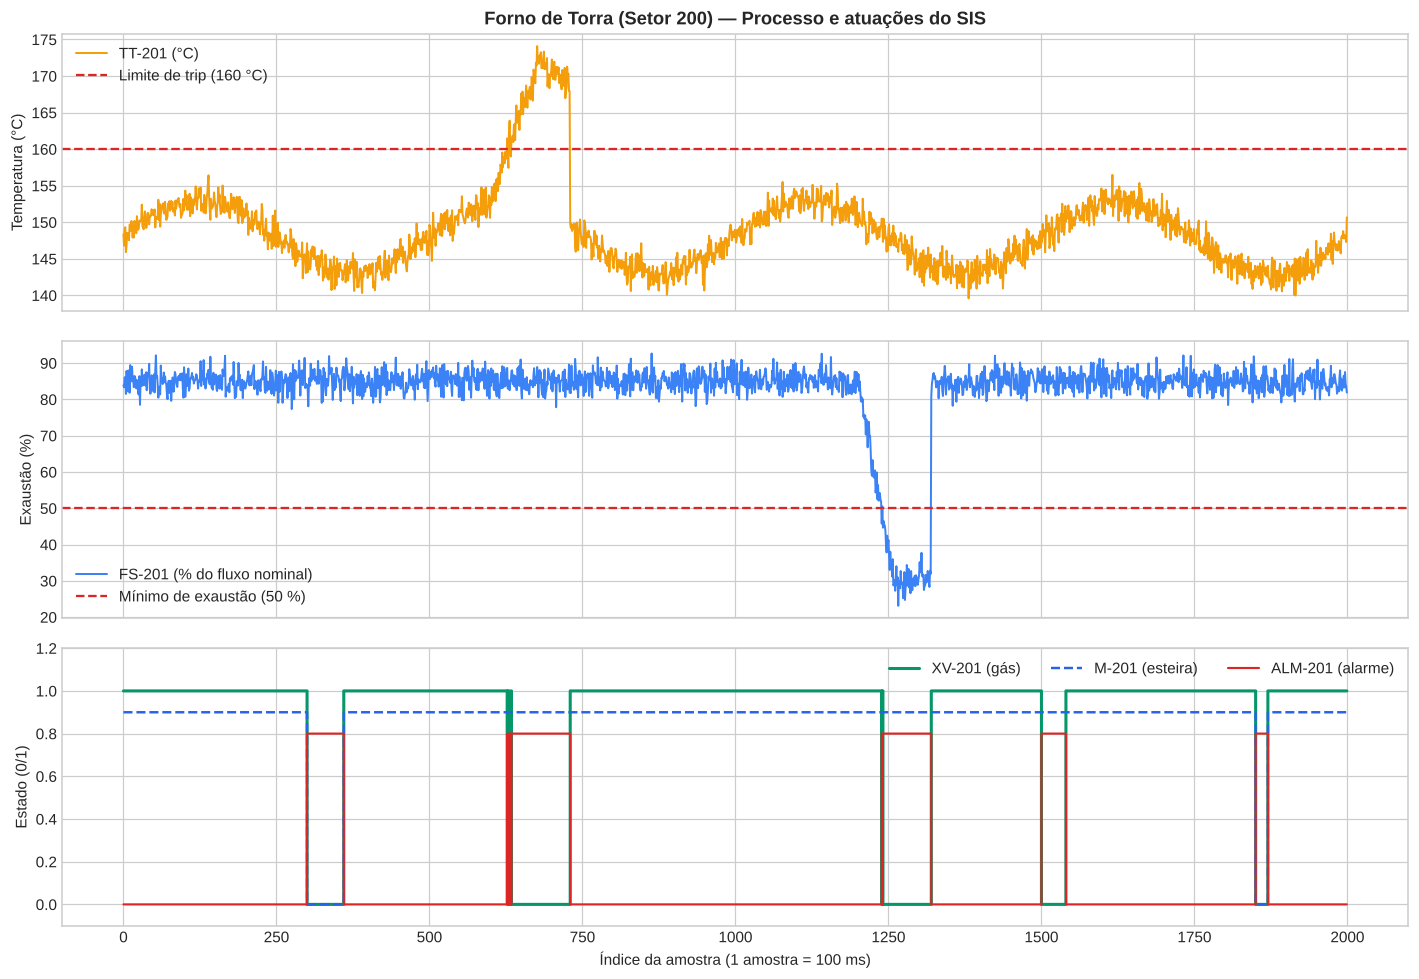

In [9]:
fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
x = np.arange(len(df))

ax[0].plot(x, df['TT_201_degC'], color='#f59e0b', lw=1.3, label='TT-201 (°C)')
ax[0].axhline(160, color='#dc2626', ls='--', label='Limite de trip (160 °C)')
ax[0].set_ylabel('Temperatura (°C)'); ax[0].legend(loc='upper left')
ax[0].set_title('Forno de Torra (Setor 200) — Processo e atuações do SIS', fontweight='bold')

ax[1].plot(x, df['FS_201_pct'], color='#3b82f6', lw=1.3, label='FS-201 (% do fluxo nominal)')
ax[1].axhline(50, color='#dc2626', ls='--', label='Mínimo de exaustão (50 %)')
ax[1].set_ylabel('Exaustão (%)'); ax[1].legend(loc='lower left')

ax[2].step(x, df['XV_201'], where='post', color='#059669', lw=2, label='XV-201 (gás)')
ax[2].step(x, df['M_201_cmd'] * 0.9, where='post', color='#2563eb', lw=1.6, ls='--', label='M-201 (esteira)')
ax[2].step(x, df['ALM_201'] * 0.8, where='post', color='#dc2626', lw=1.4, label='ALM-201 (alarme)')
ax[2].set_ylim(-0.1, 1.2); ax[2].set_ylabel('Estado (0/1)'); ax[2].legend(loc='upper right', ncol=3)
ax[2].set_xlabel('Índice da amostra (1 amostra = 100 ms)')

plt.tight_layout(); plt.show()

---
## 6. Conclusões

1. **Segurança verificada por enumeração:** nas 32 combinações possíveis de entrada, a BDT fecha `XV-201` sempre que $\neg f_2 \lor t_2 \lor e_1$ vale (regra da Etapa 01), e só mantém o gás aberto quando todas as condições seguras são verdadeiras. A profundidade é fixa ($h = 5$), então o tempo de varredura no pior caso é $O(1)$.
2. **O balanceamento é indispensável no historiador:** *timestamps* chegam em ordem crescente, o pior caso para uma BST comum (altura $= N$). A AVL manteve a altura em ~$\log_2 N$ com invariantes verificados.
3. **Consultas úteis para a operação:** busca pontual e por intervalo em $O(\log N + K)$ sustentam a RCA do trip e a rastreabilidade de lote exigida pelo APPCC.
4. **Limite do modelo:** os tempos medidos são de Python em um PC, apenas ilustrativos. O requisito de tempo real do SIS deve ser validado no CLP real (ciclo de varredura), e o SIS não deve depender do historiador.